# Road Accident Ai Alerting System

## Dataset:
https://huggingface.co/datasets/M-ArslanArshad/Car_Accidents_and_deformation_dataset

### Data Overview

> The Car Accidents and Deformation Dataset is a high-quality, manually curated collection of real-world car accident images, fully collected and annotated by the author. The dataset is intended to support machine learning tasks focused on:

> 1. Vehicle damage classification
> 2. Deformation severity estimation
> 3. Intelligent transportation systems
> 4. Insurance automation and incident reporting

### Dataset Structure
> The dataset contains two main folders: images/ and labels/, each with train/ and val/ subfolders:

```text
dataset/
├── images/
│   ├── train/
│   └── val/
├── labels/
│   ├── train/
│   └── val/
```





In [1]:
from pathlib import Path
import os
from huggingface_hub import snapshot_download

k:\Ali Turab Coding Space\Car_Accidents_and_deformation\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset_path = f"{Path().cwd()}/dataset"
print(dataset_path)
os.makedirs(dataset_path, exist_ok=True)

dataset_path = snapshot_download(
    repo_id="M-ArslanArshad/Car_Accidents_and_deformation_dataset",
    repo_type="dataset",
    local_dir=dataset_path,
)

print("Downloaded to:", dataset_path)

k:\Ali Turab Coding Space\Car_Accidents_and_deformation/dataset


Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 127.26it/s]

Downloaded to: K:\Ali Turab Coding Space\Car_Accidents_and_deformation\dataset


#### Note: Following Code is to Unzip Data nothting else 

In [3]:
from pathlib import Path
from aspose.zip.rar import RarArchive

rar_path = Path("dataset/car_accident_severity.rar")
output_dir = Path("dataset/car_accident_severity")

if not rar_path.exists():
    raise FileNotFoundError(f"Dataset not found: {rar_path}")

output_dir.mkdir(parents=True, exist_ok=True)

# Extracts purely in Python without WinRAR, 7-Zip, or external .exe tools
with RarArchive(str(rar_path)) as archive:
    print(f"Total archive entries: {len(archive.entries)}")
    archive.extract_to_directory(str(output_dir))

print("Dataset extraction completed!")
print(f"Extracted to: {output_dir.resolve()}")

Total archive entries: 2453
Dataset extraction completed!
Extracted to: K:\Ali Turab Coding Space\Car_Accidents_and_deformation\dataset\car_accident_severity


In [4]:
#checking for Dataset and Data
import pandas as pd

print(f"{dataset_path}/car_accident_severity/custom_dataset/images/train")
print(f"{dataset_path}/car_accident_severity/custom_dataset/labels/train")

K:\Ali Turab Coding Space\Car_Accidents_and_deformation\dataset/car_accident_severity/custom_dataset/images/train
K:\Ali Turab Coding Space\Car_Accidents_and_deformation\dataset/car_accident_severity/custom_dataset/labels/train


Each .txt label file follows YOLO format:
<class_id> <x_center> <y_center> <width> <height> (all normalized)

Example:
```text
4 0.560967 0.598094 0.829009 0.629283
```

## Class Labels

| Class ID | Description | Estimated Deformity |
| :---: | :--- | :---: |
| 0 | No Accident | 0% |
| 1 | Minor Accident | ~30% |
| 2 | Moderate Accident | ~50% |
| 3 | Severe Accident | ~70% |
| 4 | Totaled Vehicle | ~100% (on fire, flipped, crushed) |


## Cleaning and making Data Perfect to use in Model

Counting Data and Creating Dataframe that will have images and there boxes in the Dataset to train model Perfectly.

In [5]:
splits = [
    "dataset/car_accident_severity/custom_dataset/images/train",
    "dataset/car_accident_severity/custom_dataset/images/val",
]

for path_str in splits:
  folder = Path(path_str)
  count = len([f for f in folder.iterdir() if f.is_file()])
  
  print(f"{path_str}: {count} files")

dataset/car_accident_severity/custom_dataset/images/train: 977 files
dataset/car_accident_severity/custom_dataset/images/val: 246 files


In [6]:
train_images_folder = Path("dataset/car_accident_severity/custom_dataset/images/train")
images_data = [f.name for f in train_images_folder.iterdir() if f.is_file()]

print(len(images_data))

977


In [7]:
dataSetPath = "./dataset/car_accident_severity/custom_dataset/labels/"

data = []

def get_image_data(imageName, type="train"):
    fileName = imageName.split(".")[0]
    file_path = Path(f"{dataSetPath}/{type}/{fileName}.txt")
    
    # Check if the file actually exists
    if file_path.exists():
        lines = file_path.read_text().splitlines()
        fileData = {
            "fileName": fileName,
            "imageName": imageName,
            "target": {
                "boxes": [],
                "labels": [],
            }
        }
        
        for line in lines:
            parts = line.split()
            if not parts:  # Skip empty lines
                continue
                
            # 1. Fixed typo ("target")
            fileData["target"]["labels"].append(parts[0])
            
            # 2. Use slicing [1:] to grab everything AFTER the label
            fileData["target"]["boxes"].append(parts[1:])
            
        data.append(fileData)


{
    "fileName": abc,
    "imageName": abc.jpg,
    "target": {
        "boxes": bounding_boxes,
        "labels": class_ids
    }
}

In [8]:
for image in images_data:
    get_image_data(image)

display(data[0:5])

[{'fileName': '10_flip70',
  'imageName': '10_flip70.jpg',
  'target': {'boxes': [['0.560967', '0.598094', '0.829009', '0.629283']],
   'labels': ['4']}},
 {'fileName': '11_flip70',
  'imageName': '11_flip70.jpg',
  'target': {'boxes': [['0.568632', '0.316635', '0.240566', '0.400844'],
    ['0.252005', '0.543709', '0.491745', '0.867784']],
   'labels': ['4', '4']}},
 {'fileName': '123',
  'imageName': '123.jpg',
  'target': {'boxes': [['0.518826', '0.465313', '0.962348', '0.917090']],
   'labels': ['2']}},
 {'fileName': '123_flip50',
  'imageName': '123_flip50.jpg',
  'target': {'boxes': [['0.472847', '0.467857', '0.921580', '0.760714']],
   'labels': ['2']}},
 {'fileName': '12_flip50',
  'imageName': '12_flip50.jpg',
  'target': {'boxes': [['0.496924', '0.533036', '0.991133', '0.933928']],
   'labels': ['2']}}]

In [9]:
rows = []

for item in data:
    boxes = item["target"]["boxes"]
    labels = item["target"]["labels"]
    
    combined_data = [
        f"{label} {' '.join(box)}" 
        for label, box in zip(labels, boxes)
    ]
    
    rows.append({
        "imageName": item["imageName"],
        "data": combined_data,
        "labels": [int(l) for l in labels],
        "boxes": [[float(coord) for coord in box] for box in boxes]
    })

df = pd.DataFrame(rows)
display(df)


,imageName,data,labels,boxes
0,10_flip70.jpg,[4 0.560967 0.598094 0.829009 0.629283],[4],"[[0.560967, 0.598094, 0.829009, 0.629283]]"
1,11_flip70.jpg,"[4 0.568632 0.316635 0.240566 0.400844, 4 0.25...","[4, 4]","[[0.568632, 0.316635, 0.240566, 0.400844], [0...."
2,123.jpg,[2 0.518826 0.465313 0.962348 0.917090],[2],"[[0.518826, 0.465313, 0.962348, 0.91709]]"
3,123_flip50.jpg,[2 0.472847 0.467857 0.921580 0.760714],[2],"[[0.472847, 0.467857, 0.92158, 0.760714]]"
4,12_flip50.jpg,[2 0.496924 0.533036 0.991133 0.933928],[2],"[[0.496924, 0.533036, 0.991133, 0.933928]]"
...,...,...,...,...
972,xzza.jpg,[1 0.567845 0.430153 0.864310 0.652470],[1],"[[0.567845, 0.430153, 0.86431, 0.65247]]"
973,ybyb.jpg,"[4 0.808803 0.571066 0.382394 0.367174, 4 0.43...","[4, 4]","[[0.808803, 0.571066, 0.382394, 0.367174], [0...."
974,yhguuytfgh.jpg,"[3 0.730750 0.587134 0.538500 0.438259, 3 0.25...","[3, 3]","[[0.73075, 0.587134, 0.5385, 0.438259], [0.252..."
975,yjghsyjdsh.jpg,"[3 0.737125 0.588235 0.156250 0.205147, 0 0.87...","[3, 0, 0]","[[0.737125, 0.588235, 0.15625, 0.205147], [0.8..."


In [10]:
CLASS_NAMES = {0: "No Accident", 1: "Minor", 2: "Moderate", 3: "Severe", 4: "Totaled"}

# readable names
df["class_names"] = df["labels"].apply(lambda ls: [CLASS_NAMES[c] for c in ls])
df["num_objects"] = df["labels"].apply(len)

# one label per image (for classification): worst damage in the image
df["image_label"] = df["labels"].apply(max)
df["image_label_name"] = df["image_label"].map(CLASS_NAMES)

# class distribution (objects) and (images)
from collections import Counter
display(Counter(c for ls in df["labels"] for c in ls))
display(df["image_label_name"].value_counts())

Counter({0: 1540, 1: 483, 2: 410, 4: 302, 3: 244})

image_label_name
Moderate       283
Totaled        250
Minor          250
Severe         148
No Accident     46
Name: count, dtype: int64

In [11]:
from PIL import Image

def yolo_to_xyxy(box, img_w, img_h):
    xc, yc, w, h = box
    return [(xc - w/2) * img_w, (yc - h/2) * img_h,
            (xc + w/2) * img_w, (yc + h/2) * img_h]

img = Image.open(f"./dataset/car_accident_severity/custom_dataset/images/train/{df.imageName[0]}")
print([yolo_to_xyxy(b, *img.size) for b in df.boxes[0]])

[[102.52374999999999, 126.419815, 682.83005, 407.080033]]


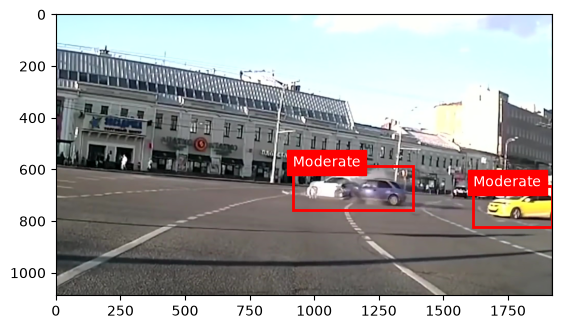

In [12]:
import matplotlib.pyplot as plt, matplotlib.patches as patches

def show(row, folder="./dataset/car_accident_severity/custom_dataset/images/train"):
    img = Image.open(f"{folder}/{row.imageName}")
    fig, ax = plt.subplots()
    ax.imshow(img)
    for box, lab in zip(row.boxes, row.labels):
        x1, y1, x2, y2 = yolo_to_xyxy(box, *img.size)
        ax.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, color="red", lw=2))
        ax.text(x1, y1, CLASS_NAMES[lab], color="white", backgroundcolor="red")
    plt.show()

show(df.iloc[976])

In [14]:
import re
from pathlib import Path

grouped_df = df.copy()

def get_original_image_name(filename):
    name = Path(filename).stem

    # Remove augmentation suffixes such as _flip70
    name = re.sub(r"_flip\d+$", "", name)

    return name


df["source_group"] = df["imageName"].apply(
    get_original_image_name
)

print(df[
    ["imageName", "source_group"]
].head(10))


        imageName source_group
0   10_flip70.jpg           10
1   11_flip70.jpg           11
2         123.jpg          123
3  123_flip50.jpg          123
4   12_flip50.jpg           12
5   12_flip70.jpg           12
6   13_flip70.jpg           13
7   14_flip70.jpg           14
8   15_flip70.jpg           15
9   16_flip70.jpg           16


In [ ]:

from sklearn.model_selection import GroupShuffleSplit

# First split: 85% train + validation, 15% test
split_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_idx, test_idx = next(
    split_1.split(
        grouped_df,
        groups=grouped_df["source_group"]
    )
)

train_val_df = grouped_df.iloc[train_val_idx].reset_index(drop=True)
test_df = grouped_df.iloc[test_idx].reset_index(drop=True)


# Second split: 70% train, 15% validation overall
split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=42
)

train_idx, val_idx = next(
    split_2.split(
        train_val_df,
        groups=train_val_df["source_group"]
    )
)

train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)


print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))


In [1]:
import torch

print("PyTorch Version:", torch.__version__)

print("CUDA Available:", torch.cuda.is_available())

print("CUDA Version:", torch.version.cuda)

print("GPU Count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

    print("Current Device:", torch.cuda.current_device())

    print("GPU Memory:", round( torch.cuda.get_device_properties(0).total_memory / 1024**3, 2 ), "GB")

PyTorch Version: 2.15.0+cu132
CUDA Available: True
CUDA Version: 13.2
GPU Count: 1
GPU Name: NVIDIA GeForce RTX 3060
Current Device: 0
GPU Memory: 12.0 GB
